In [1]:
'''Train a highly optimized Random Forest classifier, using extensive hyperparameter tuning and 
feature importance analysis to enhance the accuracy of university admission predictions.'''

'Train a highly optimized Random Forest classifier, using extensive hyperparameter tuning and \nfeature importance analysis to enhance the accuracy of university admission predictions.'

In [2]:
# import required libraries for random forest classification and evaluation

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, RandomizedSearchCV, StratifiedKFold
from sklearn.ensemble import RandomForestClassifier
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, classification_report, confusion_matrix,
    ConfusionMatrixDisplay, RocCurveDisplay
)
from sklearn.inspection import permutation_importance



In [4]:
# load the university admission dataset

df = pd.read_csv("Adm.csv")

print("dataset shape:", df.shape)
print("\nfirst five records:")
display(df.head())

print("\ndataset information:")
df.info()

dataset shape: (1000, 12)

first five records:


,Serial No.,GRE Score,TOEFL Score,University Rating,SOP,LOR,CGPA,Research,Chance of Admit,Application_DateTime,University_Name,region
0,1,337,118,4,4.5,4.5,9.65,1,0.92,2022-01-01 09:00:00,Indian Institute of Technology Kharagpur,East
1,2,324,107,4,4.0,4.5,8.87,1,0.76,2022-01-02 09:00:00,National Institute of Technology Karnataka,South
2,3,316,104,3,3.0,3.5,8.00,1,0.72,2022-01-04 09:00:00,Gujarat University,West
3,4,322,110,3,3.5,2.5,8.67,1,0.80,2022-01-06 09:00:00,Jamia Millia Islamia,North
4,5,314,103,2,2.0,3.0,8.21,0,0.65,2022-01-08 09:00:00,Jamia Millia Islamia,North



dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Serial No.            1000 non-null   int64  
 1   GRE Score             1000 non-null   int64  
 2   TOEFL Score           1000 non-null   int64  
 3   University Rating     1000 non-null   int64  
 4   SOP                   1000 non-null   float64
 5   LOR                   1000 non-null   float64
 6   CGPA                  1000 non-null   float64
 7   Research              1000 non-null   int64  
 8   Chance of Admit       1000 non-null   float64
 9   Application_DateTime  1000 non-null   object 
 10  University_Name       1000 non-null   object 
 11  region                1000 non-null   object 
dtypes: float64(4), int64(5), object(3)
memory usage: 93.9+ KB


In [5]:
# inspect missing values, duplicates and dataset statistics

print("missing values:")
print(df.isnull().sum())

print("\nduplicate records:", df.duplicated().sum())

print("\ndataset statistics:")
display(df.describe(include="all").T)

# remove duplicate records
df = df.drop_duplicates().copy()

# convert application date into datetime
df["Application_DateTime"] = pd.to_datetime(
    df["Application_DateTime"], errors="coerce"
)

# extract useful date features
df["Application_Year"] = df["Application_DateTime"].dt.year
df["Application_Month"] = df["Application_DateTime"].dt.month

# remove original date and identifier columns
df = df.drop(columns=["Serial No.", "Application_DateTime"])

print("\npreprocessed dataset:")
display(df.head())

missing values:
Serial No.              0
GRE Score               0
TOEFL Score             0
University Rating       0
SOP                     0
LOR                     0
CGPA                    0
Research                0
Chance of Admit         0
Application_DateTime    0
University_Name         0
region                  0
dtype: int64

duplicate records: 0

dataset statistics:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Serial No.,1000.0,NaN,NaN,NaN,500.5,288.819436,1.0,250.75,500.5,750.25,1000.0
GRE Score,1000.0,NaN,NaN,NaN,315.965,13.415653,290.0,305.0,316.0,326.25,340.0
TOEFL Score,1000.0,NaN,NaN,NaN,106.564,7.634277,92.0,101.0,107.0,113.0,120.0
University Rating,1000.0,NaN,NaN,NaN,3.015,1.317768,1.0,2.0,3.0,4.0,5.0
SOP,1000.0,NaN,NaN,NaN,3.3935,1.027279,0.9,2.5,3.5,4.0,5.1
LOR,1000.0,NaN,NaN,NaN,3.4067,0.891864,0.9,3.0,3.5,4.0,5.1
CGPA,1000.0,NaN,NaN,NaN,8.58979,0.61217,6.77,8.18,8.58,9.07,9.95
Research,1000.0,NaN,NaN,NaN,0.503,0.500241,0.0,0.0,1.0,1.0,1.0
Chance of Admit,1000.0,NaN,NaN,NaN,0.71777,0.14591,0.32,0.6375,0.72,0.82,0.97
Application_DateTime,1000,1000,2022-01-01 09:00:00,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN



preprocessed dataset:


,GRE Score,TOEFL Score,University Rating,SOP,LOR,CGPA,Research,Chance of Admit,University_Name,region,Application_Year,Application_Month
0,337,118,4,4.5,4.5,9.65,1,0.92,Indian Institute of Technology Kharagpur,East,2022,1
1,324,107,4,4.0,4.5,8.87,1,0.76,National Institute of Technology Karnataka,South,2022,1
2,316,104,3,3.0,3.5,8.00,1,0.72,Gujarat University,West,2022,1
3,322,110,3,3.5,2.5,8.67,1,0.80,Jamia Millia Islamia,North,2022,1
4,314,103,2,2.0,3.0,8.21,0,0.65,Jamia Millia Islamia,North,2022,1


In [6]:
# convert continuous admission chances into binary classification labels

df["Admission_Status"] = (
    df["Chance of Admit"] >= 0.70
).astype(int)

# remove original continuous target to prevent data leakage
df = df.drop(columns=["Chance of Admit"])

print("admission class distribution:")
print(df["Admission_Status"].value_counts())

print("\nclass percentages:")
print(df["Admission_Status"].value_counts(normalize=True) * 100)

admission class distribution:
Admission_Status
1    594
0    406
Name: count, dtype: int64

class percentages:
Admission_Status
1    59.4
0    40.6
Name: proportion, dtype: float64


In [7]:
# separate independent features and dependent classification target

X = df.drop(columns=["Admission_Status"])
y = df["Admission_Status"]

# identify numerical and categorical columns
numerical_features = X.select_dtypes(include=["int64", "float64"]).columns.tolist()

categorical_features = X.select_dtypes(include=["object", "category"]).columns.tolist()

print("numerical features:", numerical_features)
print("\ncategorical features:", categorical_features)

print("\ntarget shape:", y.shape)
print("feature shape:", X.shape)

numerical features: ['GRE Score', 'TOEFL Score', 'University Rating', 'SOP', 'LOR', 'CGPA', 'Research']

categorical features: ['University_Name', 'region']

target shape: (1000,)
feature shape: (1000, 11)


In [8]:
# split data while maintaining the same class distribution

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("training samples:", X_train.shape[0])
print("testing samples:", X_test.shape[0])

print("\ntraining class distribution:")
print(y_train.value_counts(normalize=True))

print("\ntesting class distribution:")
print(y_test.value_counts(normalize=True))

training samples: 800
testing samples: 200

training class distribution:
Admission_Status
1    0.59375
0    0.40625
Name: proportion, dtype: float64

testing class distribution:
Admission_Status
1    0.595
0    0.405
Name: proportion, dtype: float64


In [9]:
# handle missing values and encode categorical features automatically

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numerical_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

print("preprocessing pipeline created successfully")

preprocessing pipeline created successfully


In [10]:
# create a random forest classifier with balanced class weights

rf = RandomForestClassifier(
    random_state=42,
    class_weight="balanced",
    n_jobs=-1
)

# combine preprocessing and random forest into one pipeline
model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", rf)
])

print("random forest classifier created successfully")

random forest classifier created successfully


In [11]:
# define multiple hyperparameters for extensive model optimization

param_grid = {
    "classifier__n_estimators": [100, 150, 200, 300],
    "classifier__max_depth": [None, 5, 10, 15, 20],
    "classifier__min_samples_split": [2, 5, 10, 15],
    "classifier__min_samples_leaf": [1, 2, 4, 6],
    "classifier__max_features": ["sqrt", "log2"],
    "classifier__bootstrap": [True, False],
    "classifier__criterion": ["gini", "entropy"]
}

print("hyperparameter combinations:", 
      np.prod([len(v) for v in param_grid.values()]))

hyperparameter combinations: 2560


In [12]:
# optimize random forest parameters using randomized search and cross validation

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

random_search = RandomizedSearchCV(
    estimator=model,
    param_distributions=param_grid,
    n_iter=25,
    scoring="f1",
    cv=cv,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

# train and search for the best hyperparameters
random_search.fit(X_train, y_train)

# select the optimized model
best_model = random_search.best_estimator_

print("\nbest hyperparameters:")
print(random_search.best_params_)

print("\nbest cross-validation f1-score:",
      round(random_search.best_score_, 4))

Fitting 5 folds for each of 25 candidates, totalling 125 fits

best hyperparameters:
{'classifier__n_estimators': 300, 'classifier__min_samples_split': 5, 'classifier__min_samples_leaf': 1, 'classifier__max_features': 'log2', 'classifier__max_depth': 15, 'classifier__criterion': 'entropy', 'classifier__bootstrap': True}

best cross-validation f1-score: 0.7098


In [13]:
# generate predictions using the optimized random forest model

y_pred = best_model.predict(X_test)

# calculate probability scores for roc auc evaluation
y_probability = best_model.predict_proba(X_test)[:, 1]

print("predictions completed successfully")

print("\nfirst 10 actual values:")
print(y_test.iloc[:10].values)

print("\nfirst 10 predicted values:")
print(y_pred[:10])

predictions completed successfully

first 10 actual values:
[1 0 0 0 1 0 1 1 1 1]

first 10 predicted values:
[0 1 0 1 0 1 1 1 1 1]


In [14]:
# calculate classification performance metrics

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)
roc_auc = roc_auc_score(y_test, y_probability)

results = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1 Score", "ROC-AUC"],
    "Score": [accuracy, precision, recall, f1, roc_auc]
})

display(results.round(4))

print("\nclassification report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["Less Likely Admit", "Likely Admit"],
    zero_division=0
))

,Metric,Score
0,Accuracy,0.6450
1,Precision,0.6905
2,Recall,0.7311
3,F1 Score,0.7102
4,ROC-AUC,0.7141



classification report:
                   precision    recall  f1-score   support

Less Likely Admit       0.57      0.52      0.54        81
     Likely Admit       0.69      0.73      0.71       119

         accuracy                           0.65       200
        macro avg       0.63      0.62      0.63       200
     weighted avg       0.64      0.65      0.64       200



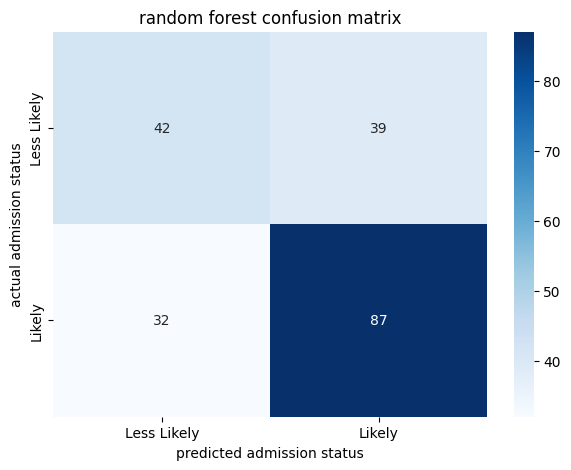

true negatives: 42
false positives: 39
false negatives: 32
true positives: 87

false positive rate: 0.4815
false negative rate: 0.2689


In [15]:
# visualize actual and predicted admission classifications

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Less Likely", "Likely"],
    yticklabels=["Less Likely", "Likely"]
)

plt.title("random forest confusion matrix")
plt.xlabel("predicted admission status")
plt.ylabel("actual admission status")
plt.show()

tn, fp, fn, tp = cm.ravel()

print("true negatives:", tn)
print("false positives:", fp)
print("false negatives:", fn)
print("true positives:", tp)

print("\nfalse positive rate:", round(fp / (fp + tn), 4))
print("false negative rate:", round(fn / (fn + tp), 4))

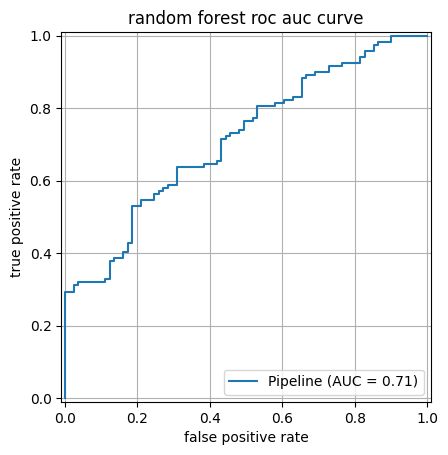

In [17]:
# evaluate the classifier ability to distinguish admission classes

from sklearn.metrics import RocCurveDisplay

RocCurveDisplay.from_estimator(
    best_model,
    X_test,
    y_test,
    pos_label=1
)

plt.title("random forest roc auc curve")
plt.xlabel("false positive rate")
plt.ylabel("true positive rate")
plt.grid()
plt.show()

In [18]:
# calculate permutation feature importance on unseen test data

importance_result = permutation_importance(
    best_model,
    X_test,
    y_test,
    scoring="f1",
    n_repeats=5,
    random_state=42,
    n_jobs=-1
)

feature_importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": importance_result.importances_mean
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

print("feature importance ranking:")
display(feature_importance.round(4))

feature importance ranking:


,Feature,Importance
5,CGPA,0.0270
0,GRE Score,0.0264
1,TOEFL Score,0.0170
8,region,0.0007
9,Application_Year,0.0000
10,Application_Month,0.0000
7,University_Name,-0.0041
6,Research,-0.0067
3,SOP,-0.0102
2,University Rating,-0.0110


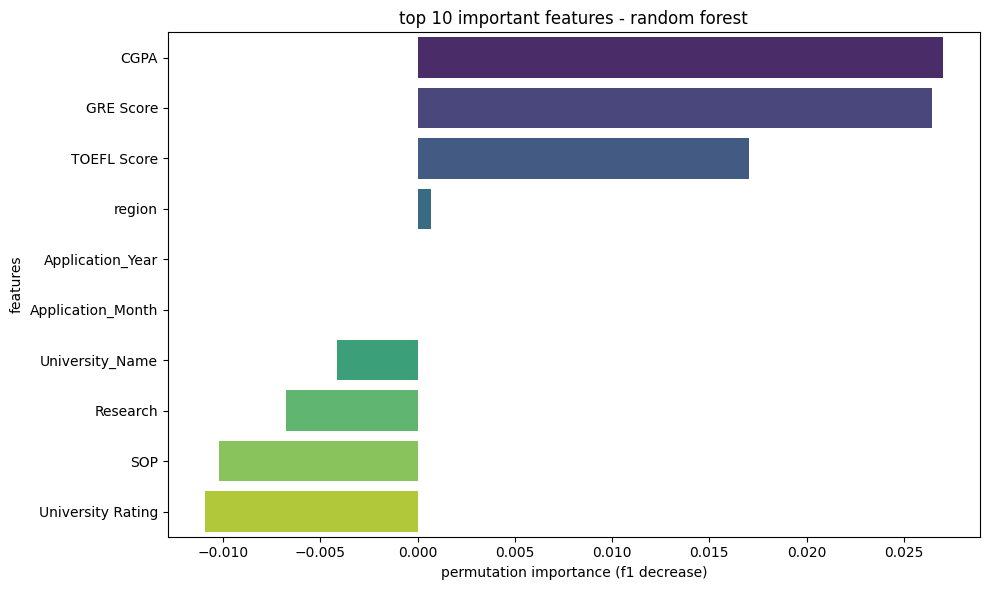

In [19]:
# display the most influential features in admission predictions

top_features = feature_importance.head(10)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=top_features,
    x="Importance",
    y="Feature",
    hue="Feature",
    palette="viridis",
    legend=False
)

plt.title("top 10 important features - random forest")
plt.xlabel("permutation importance (f1 decrease)")
plt.ylabel("features")
plt.tight_layout()
plt.show()

In [20]:
# compare actual and predicted admission status for test records

comparison = pd.DataFrame({
    "Actual Status": y_test.values,
    "Predicted Status": y_pred,
    "Admission Probability": y_probability
})

comparison["Actual Status"] = comparison["Actual Status"].map({
    0: "Less Likely Admit",
    1: "Likely Admit"
})

comparison["Predicted Status"] = comparison["Predicted Status"].map({
    0: "Less Likely Admit",
    1: "Likely Admit"
})

display(comparison.head(15))

,Actual Status,Predicted Status,Admission Probability
0,Likely Admit,Less Likely Admit,0.422130
1,Less Likely Admit,Likely Admit,0.687993
2,Less Likely Admit,Less Likely Admit,0.160764
3,Less Likely Admit,Likely Admit,0.664225
4,Likely Admit,Less Likely Admit,0.303199
5,Less Likely Admit,Likely Admit,0.698789
6,Likely Admit,Likely Admit,0.513329
7,Likely Admit,Likely Admit,0.609760
8,Likely Admit,Likely Admit,0.858030
9,Likely Admit,Likely Admit,0.573150


In [22]:
# summarize the optimized model and its evaluation results


print("algorithm: random forest classifier")
print("training records:", len(X_train))
print("testing records:", len(X_test))

print("\nbest parameters:")
for parameter, value in random_search.best_params_.items():
    print(parameter, ":", value)

print("\nmodel performance:")
print("accuracy :", round(accuracy * 100, 2), "%")
print("precision:", round(precision * 100, 2), "%")
print("recall   :", round(recall * 100, 2), "%")
print("f1 score :", round(f1 * 100, 2), "%")
print("roc auc  :", round(roc_auc, 4))

print("\ntop important feature:")
print(feature_importance.iloc[0]["Feature"])

print("\nmodel training and evaluation completed")

algorithm: random forest classifier
training records: 800
testing records: 200

best parameters:
classifier__n_estimators : 300
classifier__min_samples_split : 5
classifier__min_samples_leaf : 1
classifier__max_features : log2
classifier__max_depth : 15
classifier__criterion : entropy
classifier__bootstrap : True

model performance:
accuracy : 64.5 %
precision: 69.05 %
recall   : 73.11 %
f1 score : 71.02 %
roc auc  : 0.7141

top important feature:
CGPA

model training and evaluation completed


In [23]:
# predict admission probability for a new applicant using an existing test record

new_applicant = X_test.iloc[[0]]

prediction = best_model.predict(new_applicant)[0]
probability = best_model.predict_proba(new_applicant)[0]

print("predicted admission status:",
      "Likely Admit" if prediction == 1 else "Less Likely Admit")

print("less likely admission probability:", round(probability[0] * 100, 2), "%")
print("likely admission probability:", round(probability[1] * 100, 2), "%")

predicted admission status: Less Likely Admit
less likely admission probability: 57.79 %
likely admission probability: 42.21 %
